# Param Shah
## 240905320
### CSE-D 33
#### Lab 10: Data Clustering K-Means

## 1. Consider the following three variables for 20 different basketball players: points, assists, and rebounds.Perform k-means clustering manually with K=2, using Euclidean distance. Show the working for one iterationin your Lab Observation Book by using Euclidean distance.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.DataFrame({
    'Points':  [18, 19, 14, 14, 11, 20, 28, 30, 31, 35, 33, 25, 25, 27, 29, 30, 19, 23],
    'Assists': [3, 4, 5, 4, 7, 8, 7, 6, 9, 12, 14, 9, 4, 3, 4, 12, 15, 11]
})

print(data)

    Points  Assists
0       18        3
1       19        4
2       14        5
3       14        4
4       11        7
5       20        8
6       28        7
7       30        6
8       31        9
9       35       12
10      33       14
11      25        9
12      25        4
13      27        3
14      29        4
15      30       12
16      19       15
17      23       11


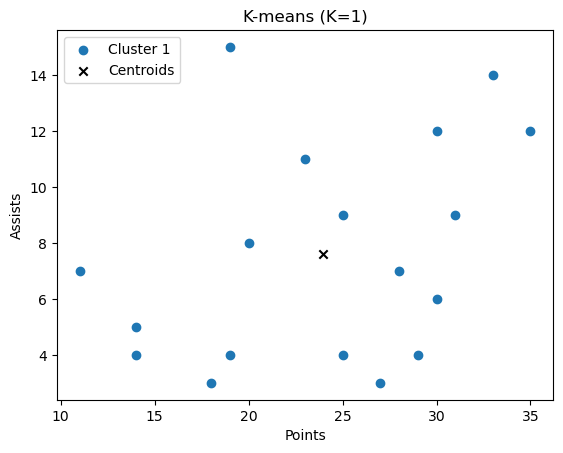

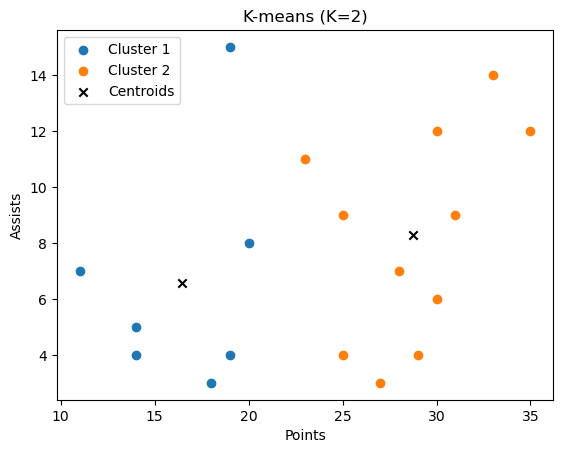

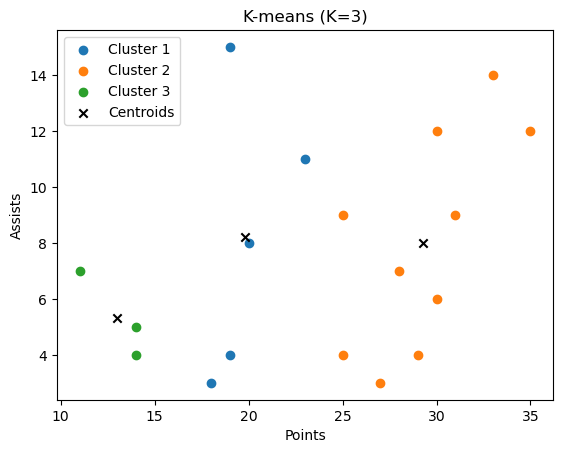

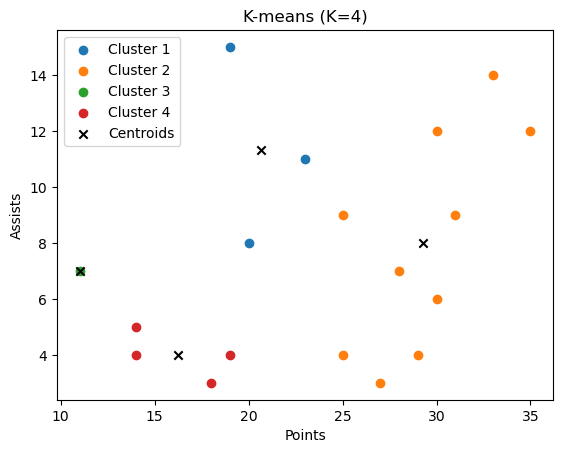

           K=1    K=2    K=3    K=4
Player                             
1        56.60  15.22  30.28   4.06
2        37.49  13.22  18.28   7.56
3       105.71   8.37   1.11   6.06
4       111.93  12.51   2.78   5.06
5       167.93  29.65   6.78   0.00
6        15.71  14.80   0.08  11.56
7        16.82   2.15   2.69   2.69
8        39.27   6.79   4.49   4.49
9        51.71   5.69   3.89   3.89
10      141.49  53.24  48.49  48.49
11      122.82  51.06  49.69  49.69
12        3.04  14.42  19.49  19.49
13       14.15  32.15  34.49  34.49
14       30.60  30.79  30.29  30.29
15       38.60  18.33  16.09  16.09
16       55.93  15.51  16.49  16.49
17       79.04  77.65  46.88  16.22
18       12.38  40.24  18.08   5.56
   K          SSE
0  1  1101.222222
1  2   441.792208
2  3   350.366667
3  4   282.183333


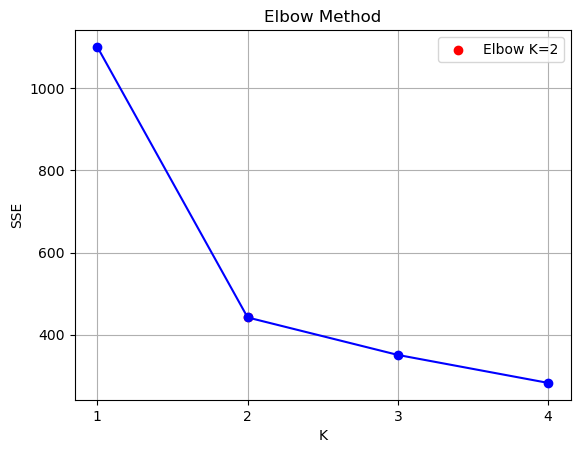

Optimal K: 2


In [20]:
def distance(a, b, method, p=3):
    d = np.abs(a - b)
    if method == 'euclidean': return np.sqrt(np.sum(d**2))
    if method == 'manhattan': return np.sum(d)
    return np.sum(d**p)**(1/p)


def kmeans(X, k, method, p=3):
    c = X[:k].copy()

    for _ in range(100):
        labels = np.array([np.argmin([distance(x, v, method, p) for v in c]) for x in X])
        new = np.array([X[labels == i].mean(axis=0) if np.any(labels == i) else c[i] for i in range(k)])
        if np.allclose(c, new): break
        c = new

    labels = np.array([np.argmin([distance(x, v, method, p) for v in c]) for x in X])
    return labels, c


X = data.values
sse_values = []
sse_table = pd.DataFrame(index=data.index + 1)

for k in range(1, 5):
    labels, centroids = kmeans(X, k, 'euclidean')
    errors = np.array([np.sum((X[i] - centroids[labels[i]])**2) for i in range(len(X))])
    sse_values.append(errors.sum())
    sse_table[f'K={k}'] = errors.round(2)

    for i in range(k):
        plt.scatter(X[labels == i, 0], X[labels == i, 1], label=f'Cluster {i+1}')

    plt.scatter(centroids[:, 0], centroids[:, 1], marker='x', color='black', label='Centroids')
    plt.xlabel('Points')
    plt.ylabel('Assists')
    plt.title(f'K-means (K={k})')
    plt.legend()
    plt.show()

sse_table.index.name = 'Player'
print(sse_table)

print(pd.DataFrame({'K': range(1, 5), 'SSE': sse_values}))

ks = np.arange(1, 5)
start, end = np.array([1, sse_values[0]]), np.array([4, sse_values[-1]])
distances = [abs(np.cross(end-start, np.array([k, s])-start)) / np.linalg.norm(end-start)
             for k, s in zip(ks, sse_values)]
optimal_k = ks[np.argmax(distances)]

plt.plot(ks, sse_values, 'bo-')
plt.scatter(optimal_k, sse_values[optimal_k-1], color='red', label=f'Elbow K={optimal_k}')
plt.xlabel('K')
plt.ylabel('SSE')
plt.title('Elbow Method')
plt.xticks(ks)
plt.legend()
plt.grid()
plt.show()

print('Optimal K:', optimal_k)

### 2. For the following 1-dimensional data points apply agglomerative hierarchical clustering to build the dendrogram.Construct the proximity matrix (distance matrix). Merge the clusters using the single linkage (min distance) and update the proximity matrix accordingly. Clearly show the proximity matrix corresponding to each iteration of the algorithm.


Proximity Matrix:
      [18]  [22]  [25]  [27]  [42]  [43]
[18]   0.0   4.0   7.0   9.0  24.0  25.0
[22]   4.0   0.0   3.0   5.0  20.0  21.0
[25]   7.0   3.0   0.0   2.0  17.0  18.0
[27]   9.0   5.0   2.0   0.0  15.0  16.0
[42]  24.0  20.0  17.0  15.0   0.0   1.0
[43]  25.0  21.0  18.0  16.0   1.0   0.0

Merge: [42] [43] Distance: 1.0

Proximity Matrix:
          [18]  [22]  [25]  [27]  [42, 43]
[18]       0.0   4.0   7.0   9.0      24.0
[22]       4.0   0.0   3.0   5.0      20.0
[25]       7.0   3.0   0.0   2.0      17.0
[27]       9.0   5.0   2.0   0.0      15.0
[42, 43]  24.0  20.0  17.0  15.0       0.0

Merge: [25] [27] Distance: 2.0

Proximity Matrix:
          [18]  [22]  [25, 27]  [42, 43]
[18]       0.0   4.0       7.0      24.0
[22]       4.0   0.0       3.0      20.0
[25, 27]   7.0   3.0       0.0      15.0
[42, 43]  24.0  20.0      15.0       0.0

Merge: [22] [25, 27] Distance: 3.0

Proximity Matrix:
              [18]  [22, 25, 27]  [42, 43]
[18]           0.0           4.

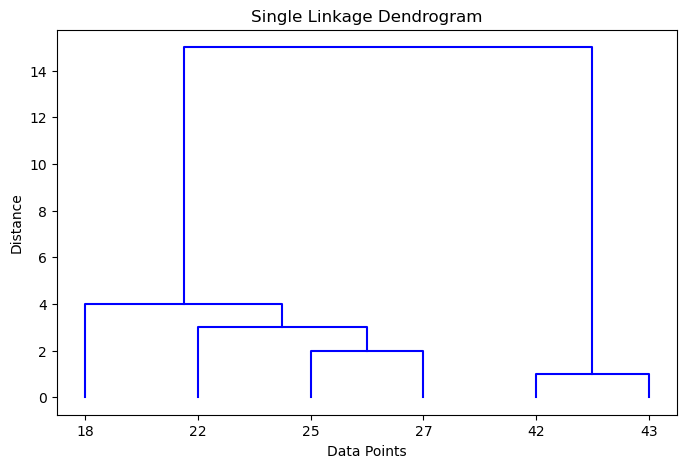

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.DataFrame({'Value': [18, 22, 25, 27, 42, 43]})
values = data['Value'].tolist()
clusters = [[x] for x in values]
merges = []

while len(clusters) > 1:
    n = len(clusters)
    matrix = np.zeros((n, n))

    for i in range(n):
        for j in range(i + 1, n):
            matrix[i, j] = matrix[j, i] = min(
                abs(a - b) for a in clusters[i] for b in clusters[j]
            )

    labels = [str(c) for c in clusters]
    print("\nProximity Matrix:")
    print(pd.DataFrame(matrix, index=labels, columns=labels))

    i, j = np.unravel_index(
        np.where(np.eye(n), np.inf, matrix).argmin(), matrix.shape
    )
    distance = matrix[i, j]
    print("\nMerge:", clusters[i], clusters[j], "Distance:", distance)
    merges.append((clusters[i][:], clusters[j][:], distance))

    clusters[i] += clusters[j]
    clusters.pop(j)

plt.figure(figsize=(8, 5))
positions = {v: i for i, v in enumerate(values)}
heights = {v: 0 for v in values}

for c1, c2, d in merges:
    x1 = np.mean([positions[v] for v in c1])
    x2 = np.mean([positions[v] for v in c2])
    plt.plot([x1, x1, x2, x2],
             [heights[c1[0]], d, d, heights[c2[0]]], 'b-')
    for v in c1 + c2:
        positions[v] = (x1 + x2) / 2
        heights[v] = d

plt.xticks(range(len(values)), values)
plt.xlabel('Data Points')
plt.ylabel('Distance')
plt.title('Single Linkage Dendrogram')
plt.show()

### Consider the following data set and apply the hierarchical data-clustering algorithm, to identify the clusters. Solve it anually by considering all linkage functions (Single, Complete and Average) using Euclidean distance.


  SINGLE LINKAGE   

Step 1 Proximity Matrix:
       {p1}  {p2}  {p3}  {p4}  {p5}   {p6}  {p7}  {p8}  {p9}
{p1}   0.00  2.24  8.00  6.32  6.08  10.00  7.62  7.28  3.00
{p2}   2.24  0.00  6.08  5.00  4.00   7.81  6.08  5.10  2.83
{p3}   8.00  6.08  0.00  8.49  2.24   6.00  8.60  2.24  8.54
{p4}   6.32  5.00  8.49  0.00  6.40   6.00  1.41  6.40  3.61
{p5}   6.08  4.00  2.24  6.40  0.00   5.39  6.71  1.41  6.32
{p6}  10.00  7.81  6.00  6.00  5.39   0.00  5.10  4.12  8.54
{p7}   7.62  6.08  8.60  1.41  6.71   5.10  0.00  6.40  5.00
{p8}   7.28  5.10  2.24  6.40  1.41   4.12  6.40  0.00  7.07
{p9}   3.00  2.83  8.54  3.61  6.32   8.54  5.00  7.07  0.00
Merge: {p4} and {p7} (Distance: 1.41)

Step 2 Proximity Matrix:
           {p1}  {p2}  {p3}  {p4, p7}  {p5}   {p6}  {p8}  {p9}
{p1}       0.00  2.24  8.00      6.32  6.08  10.00  7.28  3.00
{p2}       2.24  0.00  6.08      5.00  4.00   7.81  5.10  2.83
{p3}       8.00  6.08  0.00      8.49  2.24   6.00  2.24  8.54
{p4, p7}   6.32  5.00  8.49

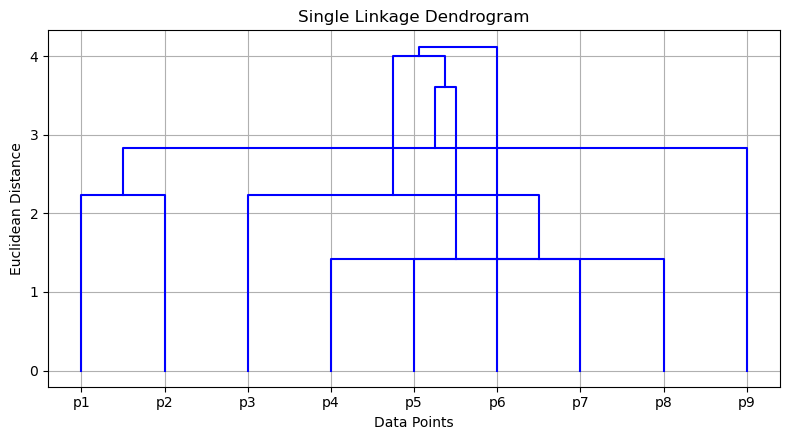


  COMPLETE LINKAGE   

Step 1 Proximity Matrix:
       {p1}  {p2}  {p3}  {p4}  {p5}   {p6}  {p7}  {p8}  {p9}
{p1}   0.00  2.24  8.00  6.32  6.08  10.00  7.62  7.28  3.00
{p2}   2.24  0.00  6.08  5.00  4.00   7.81  6.08  5.10  2.83
{p3}   8.00  6.08  0.00  8.49  2.24   6.00  8.60  2.24  8.54
{p4}   6.32  5.00  8.49  0.00  6.40   6.00  1.41  6.40  3.61
{p5}   6.08  4.00  2.24  6.40  0.00   5.39  6.71  1.41  6.32
{p6}  10.00  7.81  6.00  6.00  5.39   0.00  5.10  4.12  8.54
{p7}   7.62  6.08  8.60  1.41  6.71   5.10  0.00  6.40  5.00
{p8}   7.28  5.10  2.24  6.40  1.41   4.12  6.40  0.00  7.07
{p9}   3.00  2.83  8.54  3.61  6.32   8.54  5.00  7.07  0.00
Merge: {p4} and {p7} (Distance: 1.41)

Step 2 Proximity Matrix:
           {p1}  {p2}  {p3}  {p4, p7}  {p5}   {p6}  {p8}  {p9}
{p1}       0.00  2.24  8.00      7.62  6.08  10.00  7.28  3.00
{p2}       2.24  0.00  6.08      6.08  4.00   7.81  5.10  2.83
{p3}       8.00  6.08  0.00      8.60  2.24   6.00  2.24  8.54
{p4, p7}   7.62  6.08  8.

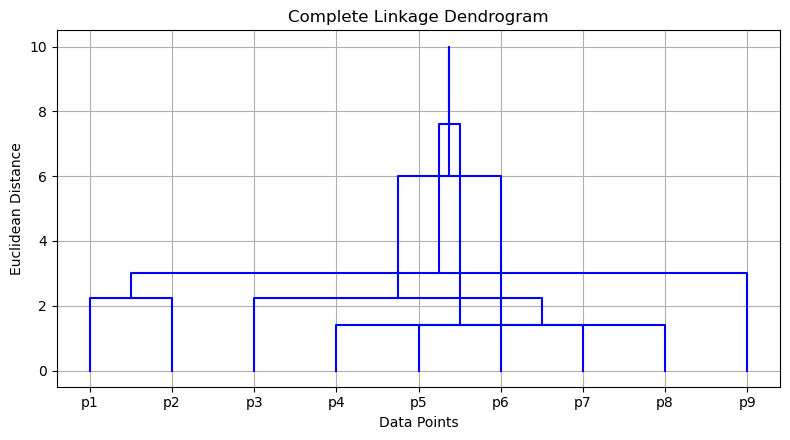


  AVERAGE LINKAGE   

Step 1 Proximity Matrix:
       {p1}  {p2}  {p3}  {p4}  {p5}   {p6}  {p7}  {p8}  {p9}
{p1}   0.00  2.24  8.00  6.32  6.08  10.00  7.62  7.28  3.00
{p2}   2.24  0.00  6.08  5.00  4.00   7.81  6.08  5.10  2.83
{p3}   8.00  6.08  0.00  8.49  2.24   6.00  8.60  2.24  8.54
{p4}   6.32  5.00  8.49  0.00  6.40   6.00  1.41  6.40  3.61
{p5}   6.08  4.00  2.24  6.40  0.00   5.39  6.71  1.41  6.32
{p6}  10.00  7.81  6.00  6.00  5.39   0.00  5.10  4.12  8.54
{p7}   7.62  6.08  8.60  1.41  6.71   5.10  0.00  6.40  5.00
{p8}   7.28  5.10  2.24  6.40  1.41   4.12  6.40  0.00  7.07
{p9}   3.00  2.83  8.54  3.61  6.32   8.54  5.00  7.07  0.00
Merge: {p4} and {p7} (Distance: 1.41)

Step 2 Proximity Matrix:
           {p1}  {p2}  {p3}  {p4, p7}  {p5}   {p6}  {p8}  {p9}
{p1}       0.00  2.24  8.00      6.97  6.08  10.00  7.28  3.00
{p2}       2.24  0.00  6.08      5.54  4.00   7.81  5.10  2.83
{p3}       8.00  6.08  0.00      8.54  2.24   6.00  2.24  8.54
{p4, p7}   6.97  5.54  8.5

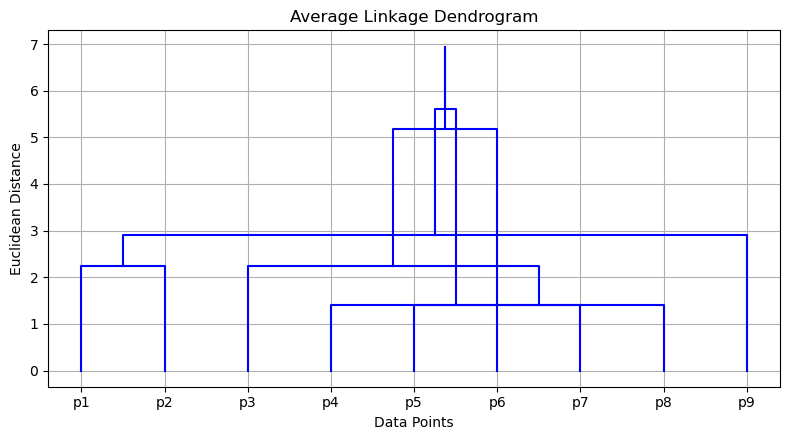

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

points = {
    'p1': (1, 1), 'p2': (3, 2), 'p3': (9, 1),
    'p4': (3, 7), 'p5': (7, 2), 'p6': (9, 7),
    'p7': (4, 8), 'p8': (8, 3), 'p9': (1, 4)
}

labels = list(points.keys())
coords = np.array([points[k] for k in labels])

def get_distance_matrix(pts):
    diff = pts[:, np.newaxis, :] - pts[np.newaxis, :, :]
    return np.sqrt(np.sum(diff ** 2, axis=-1))

dist_matrix = get_distance_matrix(coords)

def compute_cluster_dist(c1, c2, method):
    sub_matrix = dist_matrix[np.ix_(c1, c2)]
    if method == 'single':
        return np.min(sub_matrix)
    elif method == 'complete':
        return np.max(sub_matrix)
    elif method == 'average':
        return np.mean(sub_matrix)

def format_cluster(cluster_indices):
    pt_names = [labels[idx] for idx in cluster_indices]
    return f"{{{', '.join(pt_names)}}}"

def run_clustering(method):
    clusters = [[i] for i in range(len(labels))]
    merges = []
    step = 1

    print(f"\n  {method.upper()} LINKAGE   ")

    while len(clusters) > 1:
        n = len(clusters)
        matrix = np.zeros((n, n))

        for i in range(n):
            for j in range(i + 1, n):
                matrix[i, j] = matrix[j, i] = compute_cluster_dist(clusters[i], clusters[j], method)

        cluster_names = [format_cluster(c) for c in clusters]
        df_matrix = pd.DataFrame(matrix, index=cluster_names, columns=cluster_names).round(2)
        
        print(f"\nStep {step} Proximity Matrix:")
        print(df_matrix.to_string())

        i, j = np.unravel_index(np.where(np.eye(n), np.inf, matrix).argmin(), matrix.shape)
        if i > j:
            i, j = j, i

        distance = matrix[i, j]
        c1_str = format_cluster(clusters[i])
        c2_str = format_cluster(clusters[j])
        
        print(f"Merge: {c1_str} and {c2_str} (Distance: {distance:.2f})")
        
        merges.append((clusters[i][:], clusters[j][:], distance))
        clusters[i] += clusters[j]
        clusters.pop(j)
        step += 1

    plt.figure(figsize=(8, 4.5))
    positions = {i: i for i in range(len(labels))}
    heights = {i: 0.0 for i in range(len(labels))}

    for c1, c2, d in merges:
        x1 = np.mean([positions[v] for v in c1])
        x2 = np.mean([positions[v] for v in c2])
        
        plt.plot([x1, x1, x2, x2], [heights[c1[0]], d, d, heights[c2[0]]], 'b-')
        
        for v in c1 + c2:
            positions[v] = (x1 + x2) / 2.0
            heights[v] = d

    plt.xticks(range(len(labels)), labels)
    plt.xlabel('Data Points')
    plt.ylabel('Euclidean Distance')
    plt.title(f'{method.capitalize()} Linkage Dendrogram')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

for method in ['single', 'complete', 'average']:
    run_clustering(method)


Merging: [42] and [43]
Distance: 1

Updated Proximity Matrix:
          [18]  [22]  [25]  [27]  [42, 43]
[18]       0.0   4.0   7.0   9.0      24.0
[22]       4.0   0.0   3.0   5.0      20.0
[25]       7.0   3.0   0.0   2.0      17.0
[27]       9.0   5.0   2.0   0.0      15.0
[42, 43]  24.0  20.0  17.0  15.0       0.0

Merging: [25] and [27]
Distance: 2

Updated Proximity Matrix:
          [18]  [22]  [25, 27]  [42, 43]
[18]       0.0   4.0       7.0      24.0
[22]       4.0   0.0       3.0      20.0
[25, 27]   7.0   3.0       0.0      15.0
[42, 43]  24.0  20.0      15.0       0.0

Merging: [22] and [25, 27]
Distance: 3

Updated Proximity Matrix:
              [18]  [22, 25, 27]  [42, 43]
[18]           0.0           4.0      24.0
[22, 25, 27]   4.0           0.0      15.0
[42, 43]      24.0          15.0       0.0

Merging: [18] and [22, 25, 27]
Distance: 4

Updated Proximity Matrix:
                  [18, 22, 25, 27]  [42, 43]
[18, 22, 25, 27]               0.0      15.0
[42, 43]   

## 4. Consider the above-mentioned data set in Q no 1 and apply the hierarchical data-clustering algorithm, to identifythe clusters. Write a Python function (without using the scikit-learn library) to do the following:
a. Plot a scatter graph of given data points.  
b. Display the proximity matrix using Euclidean distance, Manhattan distance, and Minkowski distance.  
c. Plot the dendrogram for single, complete and average linkage methods.

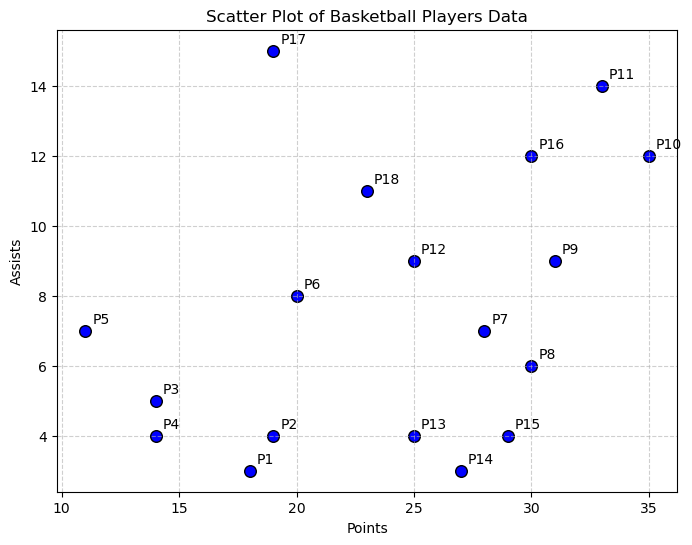

EUCLIDEAN DISTANCE MATRIX:
        P1     P2     P3     P4     P5     P6     P7     P8     P9    P10  \
P1    0.00   1.41   4.47   4.12   8.06   5.39  10.77  12.37  14.32  19.24   
P2    1.41   0.00   5.10   5.00   8.54   4.12   9.49  11.18  13.00  17.89   
P3    4.47   5.10   0.00   1.00   3.61   6.71  14.14  16.03  17.46  22.14   
P4    4.12   5.00   1.00   0.00   4.24   7.21  14.32  16.12  17.72  22.47   
P5    8.06   8.54   3.61   4.24   0.00   9.06  17.00  19.03  20.10  24.52   
P6    5.39   4.12   6.71   7.21   9.06   0.00   8.06  10.20  11.05  15.52   
P7   10.77   9.49  14.14  14.32  17.00   8.06   0.00   2.24   3.61   8.60   
P8   12.37  11.18  16.03  16.12  19.03  10.20   2.24   0.00   3.16   7.81   
P9   14.32  13.00  17.46  17.72  20.10  11.05   3.61   3.16   0.00   5.00   
P10  19.24  17.89  22.14  22.47  24.52  15.52   8.60   7.81   5.00   0.00   
P11  18.60  17.20  21.02  21.47  23.09  14.32   8.60   8.54   5.39   2.83   
P12   9.22   7.81  11.70  12.08  14.14   5.10   3

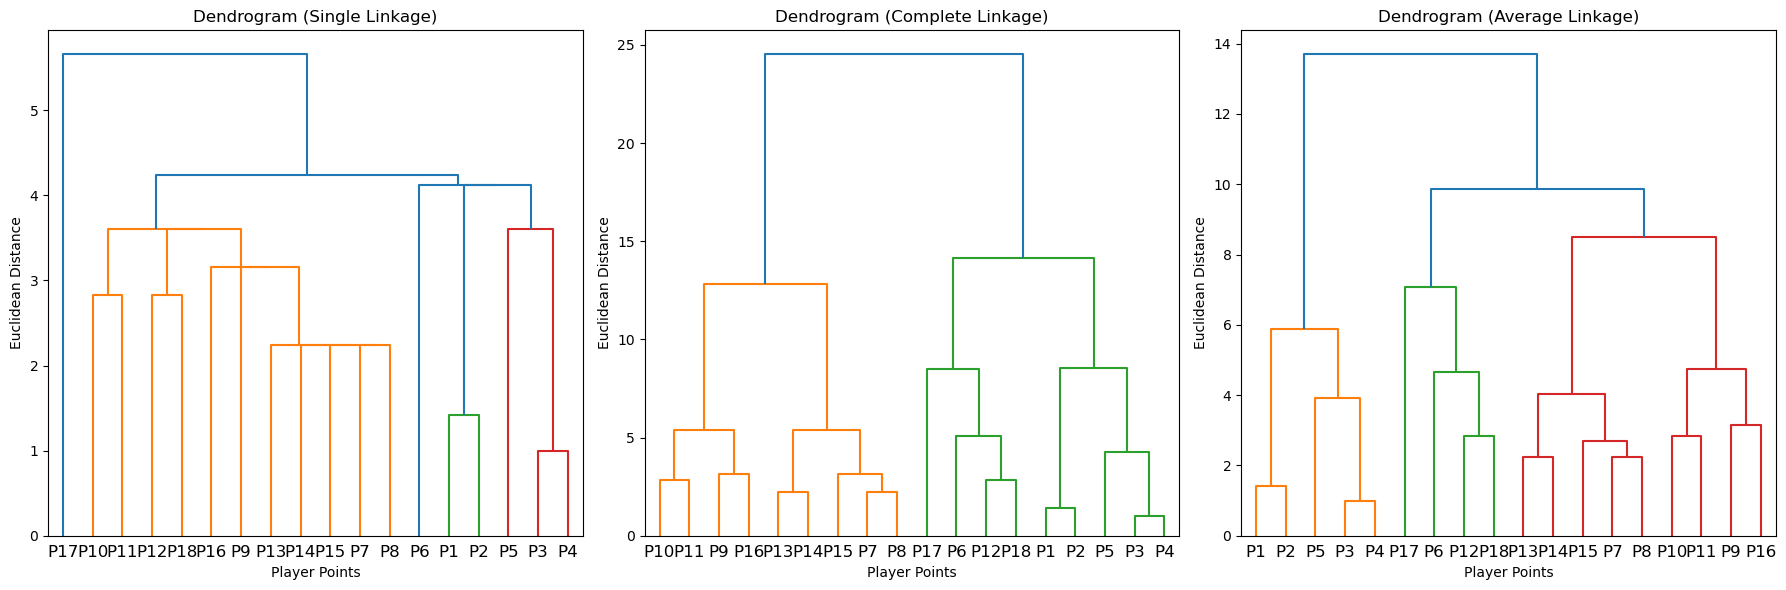

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage

data = pd.DataFrame({
    'Points':  [18, 19, 14, 14, 11, 20, 28, 30, 31, 35, 33, 25, 25, 27, 29, 30, 19, 23],
    'Assists': [3, 4, 5, 4, 7, 8, 7, 6, 9, 12, 14, 9, 4, 3, 4, 12, 15, 11]
})

X = data.values
labels = [f'P{i+1}' for i in range(len(data))]

plt.figure(figsize=(8, 6))
plt.scatter(data['Points'], data['Assists'], color='blue', edgecolors='k', s=70)
for i, txt in enumerate(labels):
    plt.annotate(txt, (data['Points'][i] + 0.3, data['Assists'][i] + 0.2))
plt.title("Scatter Plot of Basketball Players Data")
plt.xlabel("Points")
plt.ylabel("Assists")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

def calculate_distance(a, b, method='euclidean', p=3):
    diff = np.abs(a - b)
    if method == 'euclidean':
        return np.sqrt(np.sum(diff ** 2))
    elif method == 'manhattan':
        return np.sum(diff)
    elif method == 'minkowski':
        return np.sum(diff ** p) ** (1 / p)

def get_proximity_matrix(X, method='euclidean', p=3):
    n = len(X)
    matrix = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            matrix[i, j] = calculate_distance(X[i], X[j], method=method, p=p)
    return pd.DataFrame(matrix, index=labels, columns=labels)

print("EUCLIDEAN DISTANCE MATRIX:")
print(get_proximity_matrix(X, method='euclidean').round(2))

print("\nMANHATTAN DISTANCE MATRIX:")
print(get_proximity_matrix(X, method='manhattan').round(2))

print("\nMINKOWSKI DISTANCE MATRIX (p=3):")
print(get_proximity_matrix(X, method='minkowski', p=3).round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, method in zip(axes, ['single', 'complete', 'average']):
    Z = linkage(X, method=method, metric='euclidean')
    dendrogram(Z, labels=labels, ax=ax)
    ax.set_title(f"Dendrogram ({method.capitalize()} Linkage)")
    ax.set_xlabel("Player Points")
    ax.set_ylabel("Euclidean Distance")

plt.tight_layout()
plt.show()